In [2]:
import pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#loads a toolbox, np as a nickname
#path makes it so the files can step to the level we need

DATA_DIR = Path.cwd().parent.parent / "ppg+dalia" / "PPG_FieldStudy"
print("Data folder found:", DATA_DIR.exists())

Data folder found: True


In [4]:
with open(DATA_DIR / "S1" / "S1.pkl", "rb") as f:
    data = pickle.load(f, encoding="latin1")

In [5]:
FS_PPG, FS_ACC, FS_ECG, FS_ACTIVITY = 64, 32, 700, 4

ppg = data["signal"]["wrist"]["BVP"][:, 0]
acc = data["signal"]["wrist"]["ACC"]
ecg = data["signal"]["chest"]["ECG"][:, 0]
rpeaks = data["rpeaks"]
hr = data["label"]
activity = data["activity"][:, 0].astype(int)

for name, signal, fs in [("PPG", ppg, FS_PPG), ("ACC", acc, FS_ACC),
                         ("ECG", ecg, FS_ECG), ("activity", activity, FS_ACTIVITY)]:
    print(f"{name:<9} {len(signal):>9} samples / {fs:>3} Hz = {len(signal)/fs/60:6.1f} minutes")

print(f"HR labels: {len(hr)} windows, from {hr.min():.0f} to {hr.max():.0f} bpm")

PPG          589568 samples /  64 Hz =  153.5 minutes
ACC          294784 samples /  32 Hz =  153.5 minutes
ECG         6448400 samples / 700 Hz =  153.5 minutes
activity      36848 samples /   4 Hz =  153.5 minutes
HR labels: 4603 windows, from 42 to 150 bpm


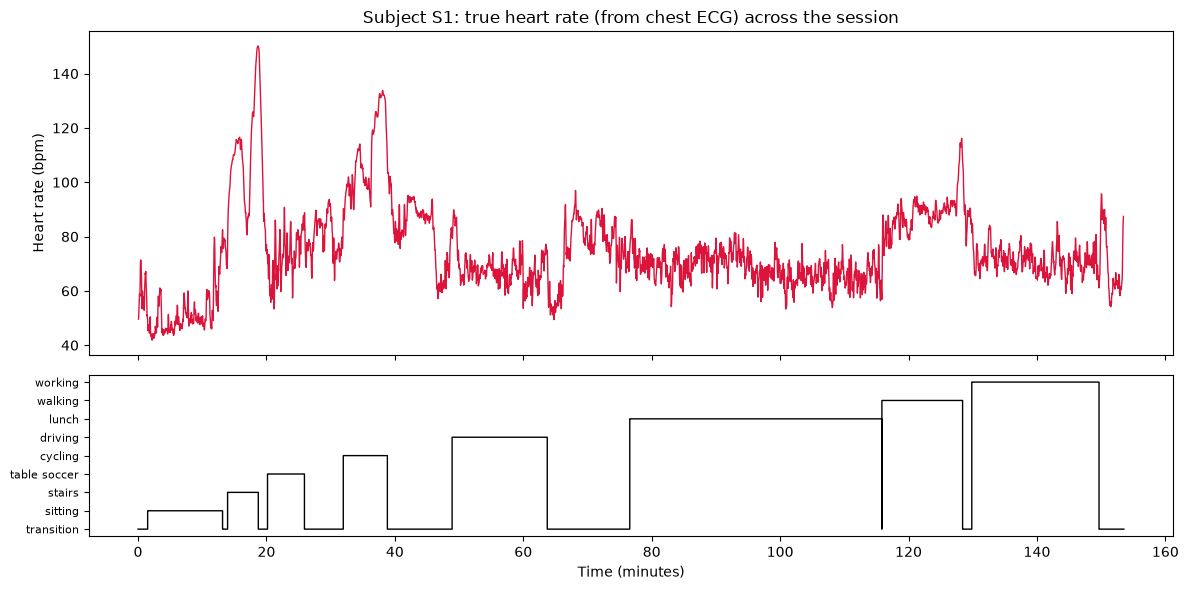

In [6]:
ACTIVITY_NAMES = {0: "transition", 1: "sitting", 2: "stairs", 3: "table soccer", 4: "cycling",
                  5: "driving", 6: "lunch", 7: "walking", 8: "working"}

hr_time_min = (np.arange(len(hr)) * 2 + 4) / 60
activity_time_min = np.arange(len(activity)) / FS_ACTIVITY / 60

fig, (ax_hr, ax_act) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                                    gridspec_kw={"height_ratios": [2, 1]})
ax_hr.plot(hr_time_min, hr, color="crimson", linewidth=1)
ax_hr.set_ylabel("Heart rate (bpm)")
ax_hr.set_title("Subject S1: true heart rate (from chest ECG) across the session")

ax_act.step(activity_time_min, activity, where="post", color="black", linewidth=1)
ax_act.set_yticks(list(ACTIVITY_NAMES))
ax_act.set_yticklabels(list(ACTIVITY_NAMES.values()), fontsize=8)
ax_act.set_xlabel("Time (minutes)")
plt.tight_layout()
plt.show()

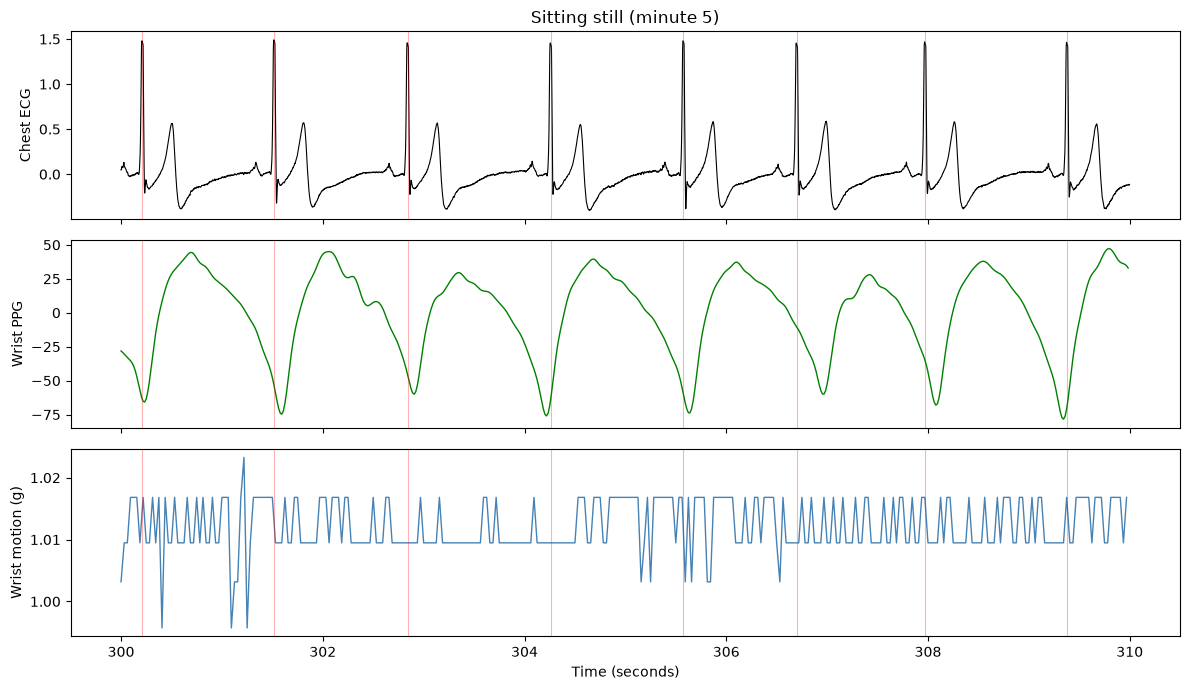

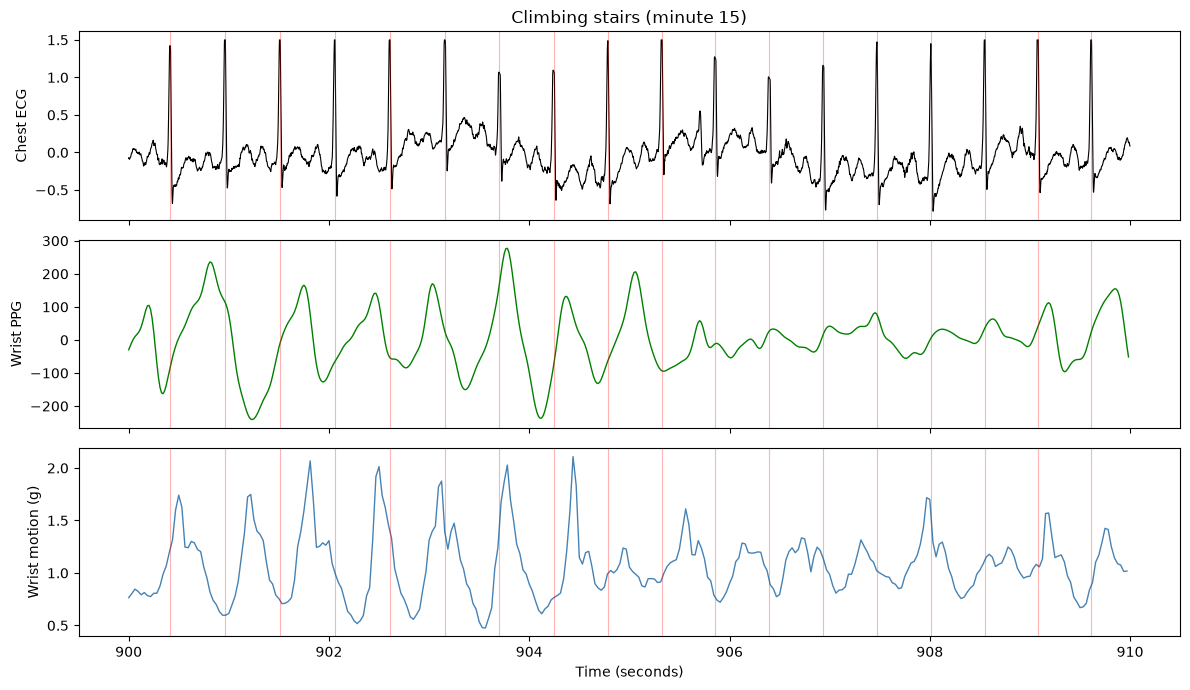

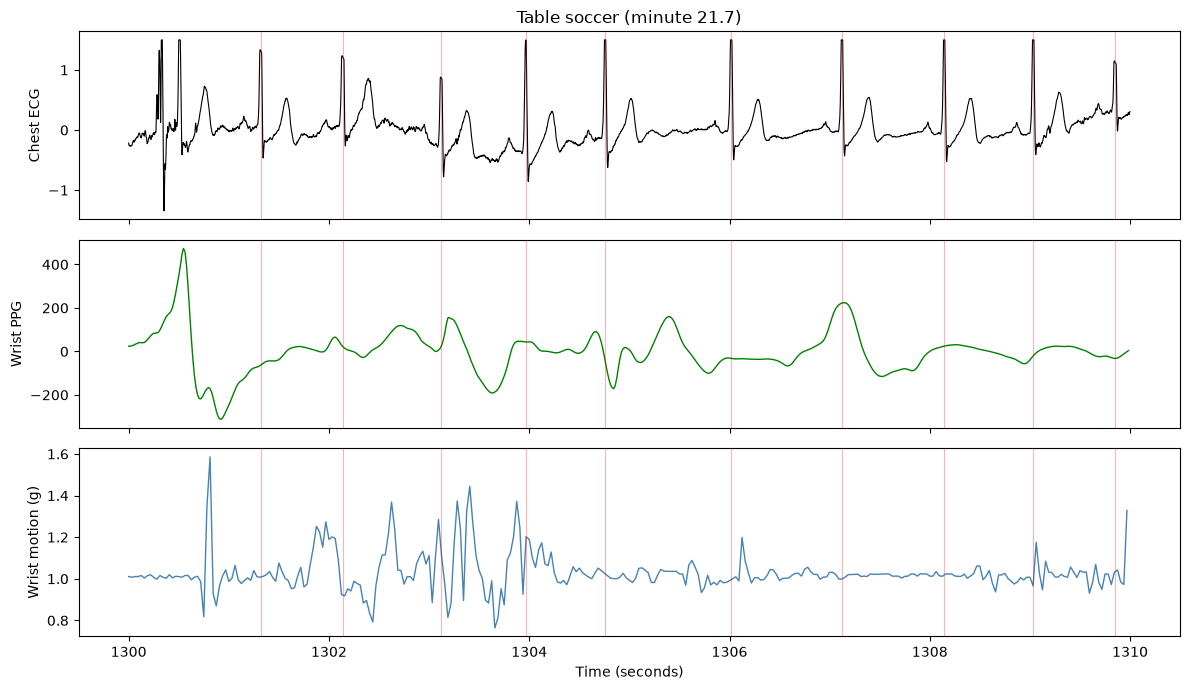

In [7]:
def plot_snippet(start_s, length_s=10, title=""):
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

    i0, i1 = int(start_s * FS_ECG), int((start_s + length_s) * FS_ECG)
    axes[0].plot(np.arange(i0, i1) / FS_ECG, ecg[i0:i1], color="black", linewidth=0.8)
    axes[0].set_ylabel("Chest ECG")

    i0, i1 = int(start_s * FS_PPG), int((start_s + length_s) * FS_PPG)
    axes[1].plot(np.arange(i0, i1) / FS_PPG, ppg[i0:i1], color="green", linewidth=1)
    axes[1].set_ylabel("Wrist PPG")

    i0, i1 = int(start_s * FS_ACC), int((start_s + length_s) * FS_ACC)
    motion = np.linalg.norm(acc[i0:i1], axis=1)
    axes[2].plot(np.arange(i0, i1) / FS_ACC, motion, color="steelblue", linewidth=1)
    axes[2].set_ylabel("Wrist motion (g)")
    axes[2].set_xlabel("Time (seconds)")

    beats = rpeaks[(rpeaks >= start_s * FS_ECG) & (rpeaks < (start_s + length_s) * FS_ECG)] / FS_ECG
    for ax in axes:
        for b in beats:
            ax.axvline(b, color="red", alpha=0.3, linewidth=0.8)

    axes[0].set_title(title)
    plt.tight_layout()
    plt.show()

plot_snippet(300, title="Sitting still (minute 5)")
plot_snippet(900, title="Climbing stairs (minute 15)")
plot_snippet(1300, title="Table soccer (minute 21.7)")